In [1]:
import math
import random

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

In [2]:
rng = np.random.default_rng()

## Линейная регрессия

Строя модели машинного обучения мы фактически пытаемся найти функциональную зависимость между данными и целевой переменной.

Один из видов такой зависимости является линейная зависимость

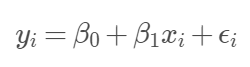

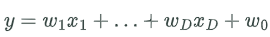

### Как найти весовые коэффициенты?

In [3]:
linear_data_rng = np.random.default_rng(42)
coefficient_rng = np.random.default_rng()
linear_feature = np.linspace(-1, 1, 80)
linear_noise = linear_data_rng.normal(0, 0.35, len(linear_feature))
linear_target = 3 * linear_feature + 2 + linear_noise
linear_grid = np.linspace(-1, 1, 300)

Попробуем случайные (ну а вдруг?)

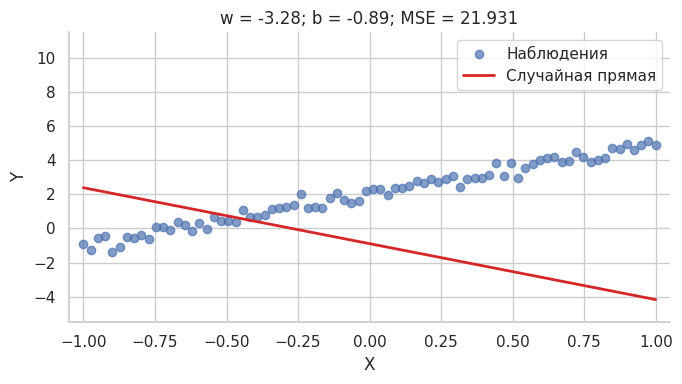

In [4]:
random_weight = coefficient_rng.uniform(-4, 6)
random_intercept = coefficient_rng.uniform(-1, 5)
random_prediction = random_weight * linear_feature + random_intercept
random_mse = mean_squared_error(linear_target, random_prediction)

plt.figure(figsize=(7, 4))
plt.scatter(linear_feature, linear_target, alpha=0.7, label='Наблюдения')
plt.plot(linear_grid, random_weight * linear_grid + random_intercept, color='tab:red', linewidth=2, label='Случайная прямая')
plt.title(f'w = {random_weight:.2f}; b = {random_intercept:.2f}; MSE = {random_mse:.3f}')
plt.xlabel('X')
plt.ylabel('Y')
plt.xlim(-1.05, 1.05)
plt.ylim(-5.5, 11.5)
plt.legend()
plt.tight_layout()
plt.show()

В принципе неплохо, но можно лучше...

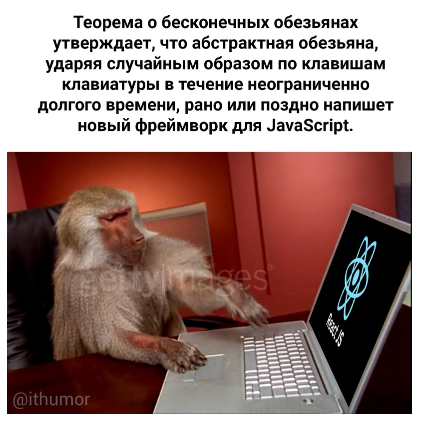

Если вдуматься, даже случайно подбирая веса, мы решаем оптимизационную задачу вида

$w^* = argmin(F(w | X, Y))$, где $F$ — некий функционал («ошибка алгоритма», функция потерь, loss function).


Мы хотим, чтобы на нашем датасете функция  как можно лучше приближала нашу зависимость. Для этого минимизируется MSE

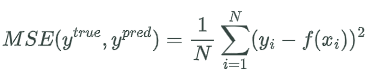


Или MAE (например, когда есть выбросы)

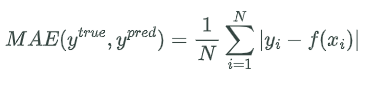

Или что-нибудь еще...

### Как будем решать оптимизационную задачу?

#### Градиентный спуск

[Градиент](https://ru.wikipedia.org/wiki/%D0%93%D1%80%D0%B0%D0%B4%D0%B8%D0%B5%D0%BD%D1%82) - вектор, своим направлением указывающий направление наискорейшего роста функции $\varphi$

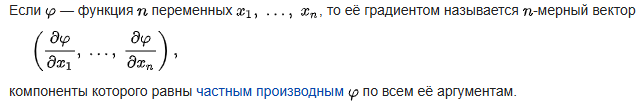

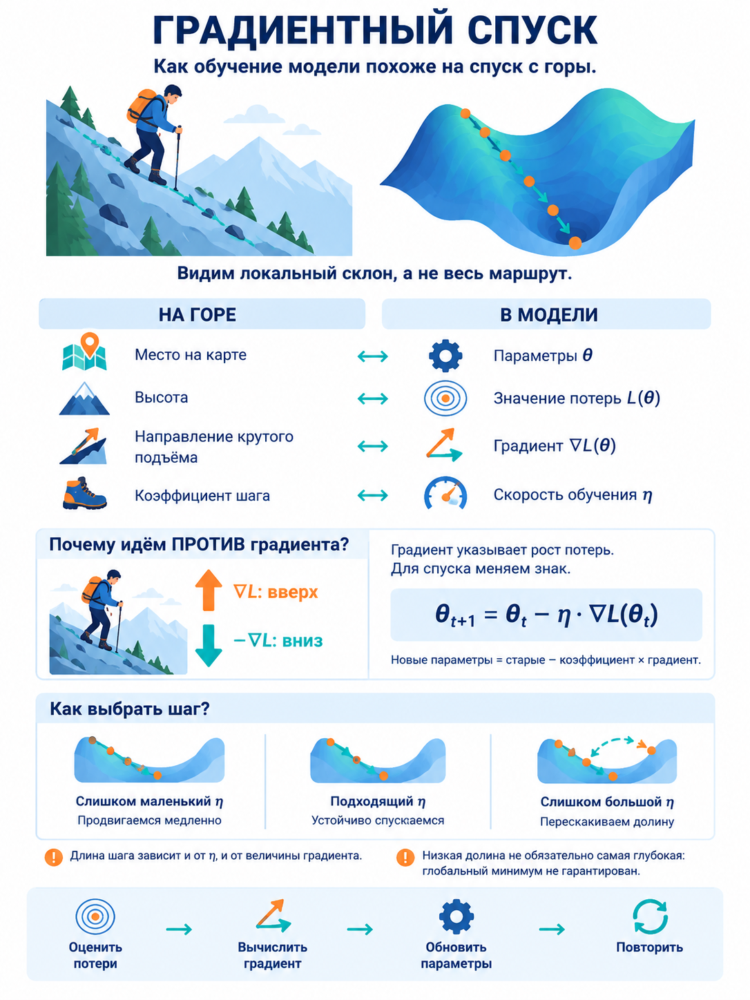

#### Соберем все вместе

$$L(w,b)=\frac1n\sum_{i=1}^{n}(wx_i+b-y_i)^2.$$

MSE здесь выполняет роль функции потерь.

Введём остаток $$r_i=\hat y_i-y_i$$

Тогда градиенты:

$$
\frac{\partial L}{\partial w}=\frac2n\sum_i x_ir_i,
\qquad
\frac{\partial L}{\partial b}=\frac2n\sum_i r_i.
$$

In [5]:
def fit_gradient_descent(feature, target, learning_rate=0.2, initial_weight=0.0,
    initial_intercept=0.0, max_iterations=20000, gradient_tolerance=1e-8, regularization_strength=0.0,
):
    weight, intercept = initial_weight, initial_intercept
    history = []

    for iteration in range(max_iterations + 1):
        residual = weight * feature + intercept - target
        mse = np.mean(residual ** 2)
        penalty = regularization_strength * weight ** 2

        dw = 2 * np.mean(feature * residual) + 2 * regularization_strength * weight
        db = 2 * np.mean(residual)
        gradient_norm = np.hypot(dw, db)

        history.append({"iteration": iteration, "weight": weight, "intercept": intercept, "mse": mse,})

        if gradient_norm < gradient_tolerance:
            break

        if iteration == max_iterations:
            break

        weight -= learning_rate * dw
        intercept -= learning_rate * db

    return {"weight": weight, "intercept": intercept, "history": pd.DataFrame(history)}


linear_fit = fit_gradient_descent(linear_feature, linear_target)
last_step = linear_fit["history"].iloc[-1]

linear_fit_summary = pd.Series({"weight": linear_fit["weight"], "intercept": linear_fit["intercept"], "mse": last_step["mse"]})
linear_fit_summary

,0
weight,2.992644
intercept,2.009002
mse,0.072523


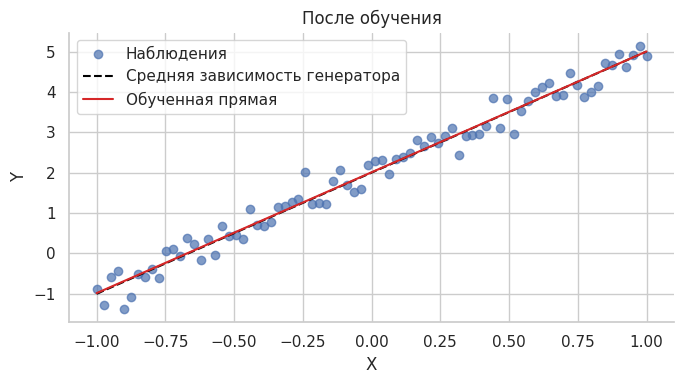

In [6]:
plt.figure(figsize=(7, 4))
plt.scatter(linear_feature, linear_target, alpha=0.7, label='Наблюдения')
plt.plot(linear_grid, 3 * linear_grid + 2, color='black', linestyle='--', label='Средняя зависимость генератора')
plt.plot(linear_grid, linear_fit['weight'] * linear_grid + linear_fit['intercept'], color='tab:red', label='Обученная прямая')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('После обучения')
plt.legend()
plt.tight_layout()
plt.show()

#### Посмотрим на линии уровня

In [7]:
weight_values = np.linspace(-0.5, 4, 120)
intercept_values = np.linspace(-0.5, 3, 120)
parameter_mesh = np.meshgrid(weight_values, intercept_values)
weight_mesh = parameter_mesh[0]
intercept_mesh = parameter_mesh[1]
loss_surface = np.mean((weight_mesh[..., None] * linear_feature + intercept_mesh[..., None] - linear_target) ** 2, axis=-1)

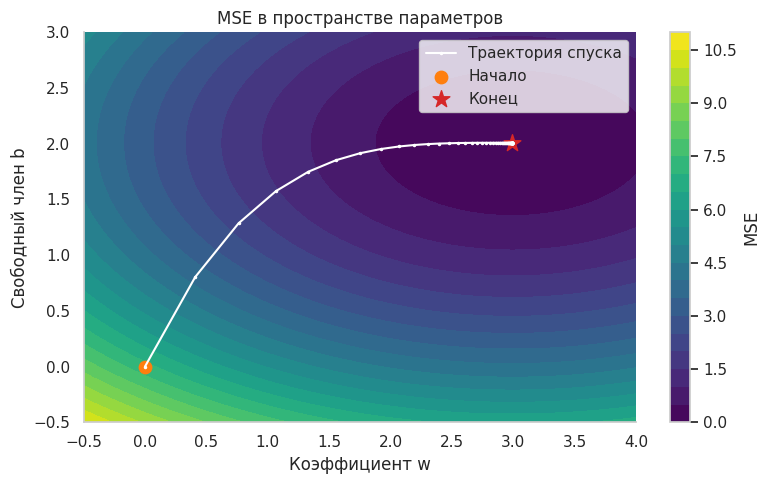

In [8]:
plt.figure(figsize=(8, 5))
contour_plot = plt.contourf(weight_mesh, intercept_mesh, loss_surface, levels=25, cmap='viridis')
plt.colorbar(contour_plot, label='MSE')
plt.plot(linear_fit['history']['weight'], linear_fit['history']['intercept'], color='white', marker='.', markersize=3, label='Траектория спуска')
plt.scatter([0], [0], color='tab:orange', s=80, label='Начало')
plt.scatter([linear_fit['weight']], [linear_fit['intercept']], color='tab:red', marker='*', s=160, label='Конец')
plt.xlabel('Коэффициент w')
plt.ylabel('Свободный член b')
plt.title('MSE в пространстве параметров')
plt.legend()
plt.tight_layout()
plt.show()

### Готовая реализация в Scikit-Learn

In [9]:
linear_feature_matrix = linear_feature.reshape(-1, 1)
lr = LinearRegression()
lr.fit(linear_feature_matrix, linear_target)
linear_reference_prediction = lr.predict(linear_feature_matrix)

lr.coef_[0], lr.intercept_, mean_squared_error(linear_target, linear_reference_prediction)

(np.float64(2.99264389189209),
 np.float64(2.009002410902145),
 0.07252271228469227)

### Масштабирование

Умножим признак на 1000

In [10]:
large_scale_feature = 1000 * linear_feature
lr_scale = LinearRegression()
lr_scale.fit(large_scale_feature.reshape(-1, 1), linear_target)
large_scale_prediction = lr_scale.predict(large_scale_feature.reshape(-1, 1))
unit_comparison = pd.DataFrame([
    {'units': 'x', 'weight': lr.coef_[0], 'intercept': lr.intercept_, 'mse': mean_squared_error(linear_target, linear_reference_prediction)},
     {'units': '1000 * x', 'weight': lr_scale.coef_[0], 'intercept': lr_scale.intercept_, 'mse': mean_squared_error(linear_target, large_scale_prediction)}])
unit_comparison.round(8)

,units,weight,intercept,mse
0,x,2.992644,2.009002,0.072523
1,1000 * x,0.002993,2.009002,0.072523


#### StandardScaler

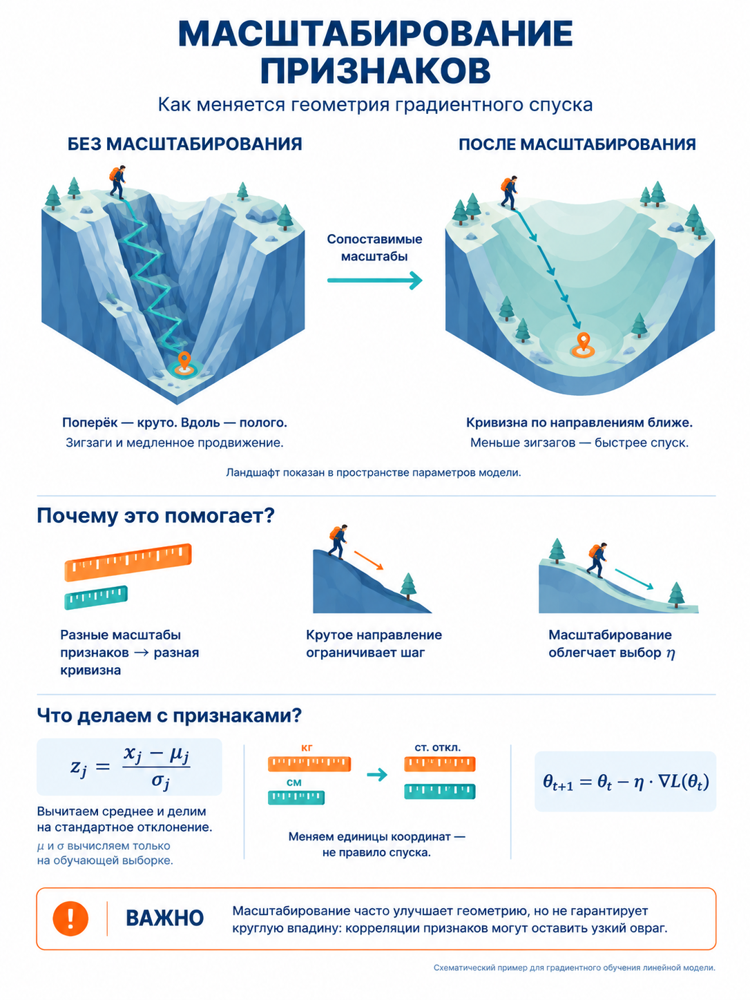

`StandardScaler` вычитает обучающее среднее и делит на обучающее стандартное отклонение. Он не требует нормального распределения и не превращает распределение в нормальное. Масштабирование не является обязательным условием хорошего прогноза, но для градиентного спуска меняет геометрию задачи.

In [11]:
scaler = StandardScaler()
standardized_feature = scaler.fit_transform(large_scale_feature.reshape(-1, 1)).ravel()
experiments = {}
experiments['Исходный признак, шаг 0.2'] = fit_gradient_descent(linear_feature, linear_target, learning_rate=0.2, max_iterations=120)
experiments['1000 * x, шаг 0.2'] = fit_gradient_descent(large_scale_feature, linear_target, learning_rate=0.2, max_iterations=120)
experiments['Стандартизация, шаг 0.2'] = fit_gradient_descent(standardized_feature, linear_target, learning_rate=0.2, max_iterations=120)
experiments['1000 * x, шаг 0.000001'] = fit_gradient_descent(large_scale_feature, linear_target, learning_rate=0.000001, max_iterations=120)
scale_summary = pd.DataFrame([{'experiment': name, 'mse': result['history']['mse'].iloc[-1], 'updates': result['history']['iteration'].iloc[-1]} for name, result in experiments.items()])
scale_summary

/tmp/ipykernel_14725/1311615299.py:9: RuntimeWarning: overflow encountered in square
  mse = np.mean(residual ** 2)
/tmp/ipykernel_14725/1311615299.py:10: RuntimeWarning: overflow encountered in scalar power
  penalty = regularization_strength * weight ** 2
/tmp/ipykernel_14725/1311615299.py:10: RuntimeWarning: invalid value encountered in scalar multiply
  penalty = regularization_strength * weight ** 2
/tmp/ipykernel_14725/1311615299.py:8: RuntimeWarning: overflow encountered in multiply
  residual = weight * feature + intercept - target
/tmp/ipykernel_14725/1311615299.py:12: RuntimeWarning: overflow encountered in multiply
  dw = 2 * np.mean(feature * residual) + 2 * regularization_strength * weight
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:136: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_14725/1311615299.py:12: RuntimeWarning: invalid value encountered in scalar multiply
  dw 

,experiment,mse,updates
0,"Исходный признак, шаг 0.2",0.072523,120
1,"1000 * x, шаг 0.2",NaN,120
2,"Стандартизация, шаг 0.2",0.072523,40
3,"1000 * x, шаг 0.000001",4.106677,120


🚩 Сейчас все точки используются для демонстрации оптимизации, далее любой обучаемый скейлер рассчитываем только на train. На validation и test применяем тот же `transform`, не повторяя `fit`!

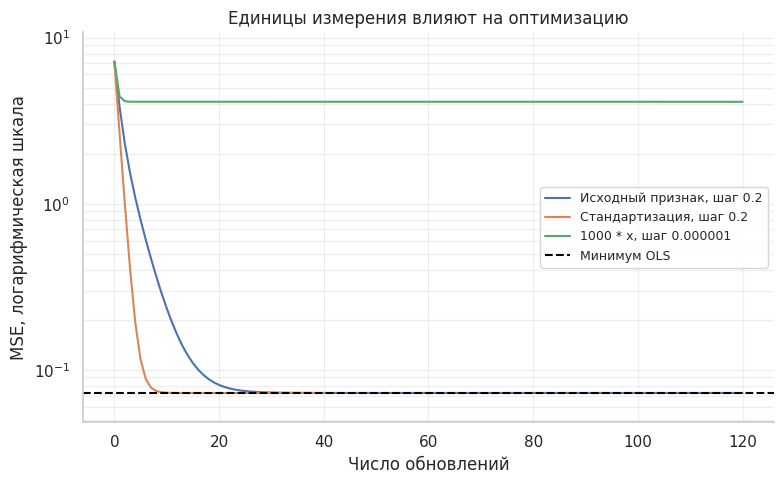

In [12]:
ols_mse = mean_squared_error(linear_target, linear_reference_prediction)

fig, ax = plt.subplots(figsize=(8, 5))
positive_mse = []
initial_mse = []

for name, result in experiments.items():
    if name == '1000 * x, шаг 0.2':
        continue

    history = result['history']
    mse = history['mse'].to_numpy()
    iterations = history['iteration'].to_numpy()
    valid = np.isfinite(mse) & (mse > 0)

    ax.plot(iterations[valid], mse[valid], label=name)

    positive_mse.extend(mse[valid])
    initial_mse.append(mse[0])

if ols_mse > 0:
    ax.axhline(ols_mse, color='black', linestyle='--', label='Минимум OLS')
    positive_mse.append(ols_mse)

ax.set_yscale('log')
ax.set_ylim(min(positive_mse) / 1.5, max(initial_mse) * 1.5)
ax.set_xlabel('Число обновлений')
ax.set_ylabel('MSE, логарифмическая шкала')
ax.set_title('Единицы измерения влияют на оптимизацию')
ax.legend(fontsize=9)
ax.grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()

### Влияние выбросов

In [13]:
rng = np.random.default_rng(91)
x_val = np.linspace(-1, 1, 100)
y_val = 3 * x_val + 2 + rng.normal(0, 0.35, len(x_val))
X_val = x_val.reshape(-1, 1)

scenarios = {'Обычные данные': None, 'Точка в центре': (0, 14), 'Точка у края': (1, 17)}
models, rows = {}, []

for name, point in scenarios.items():
    x, y = linear_feature, linear_target
    if point is not None:
        x, y = np.append(x, point[0]), np.append(y, point[1])

    X = x.reshape(-1, 1)
    model = LinearRegression().fit(X, y)
    models[name] = model

    rows.append({
        'scenario': name,
        'weight': model.coef_[0],
        'intercept': model.intercept_,
        'train_mse': mean_squared_error(y, model.predict(X)),
        'validation_mse': mean_squared_error(y_val, model.predict(X_val)),
    })

influence_metrics = pd.DataFrame(rows)
influence_metrics.round(4)

,scenario,weight,intercept,train_mse,validation_mse
0,Обычные данные,2.9926,2.009,0.0725,0.1000
1,Точка в центре,2.9926,2.157,1.8248,0.1066
2,Точка у края,3.4109,2.152,1.7658,0.1660


Точка с отклонением по y может заметно влиять через квадрат ошибки!

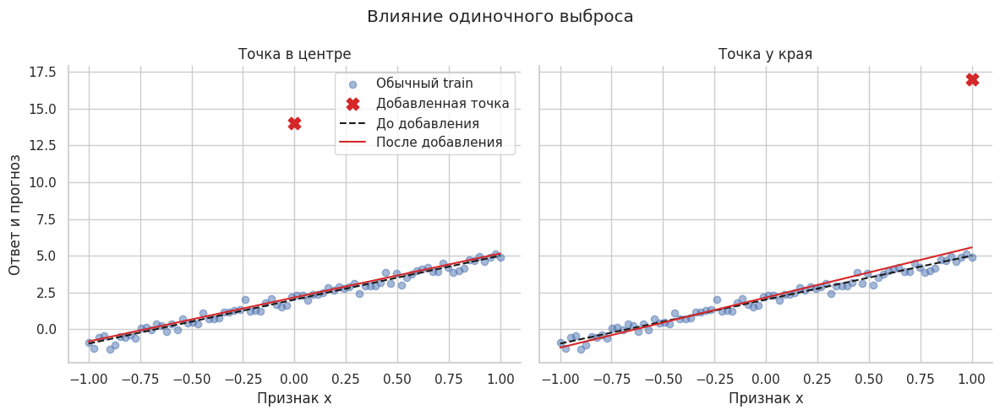

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
X_grid = linear_grid.reshape(-1, 1)
baseline = models['Обычные данные'].predict(X_grid)

for ax, name in zip(axes, ['Точка в центре', 'Точка у края']):
    ax.scatter(linear_feature, linear_target, alpha=0.5, label='Обычный train')
    ax.scatter(*scenarios[name], color='tab:red', marker='X', s=110, label='Добавленная точка')
    ax.plot(linear_grid, baseline, 'k--', label='До добавления')
    ax.plot(linear_grid, models[name].predict(X_grid), color='tab:red', label='После добавления')
    ax.set(title=name, xlabel='Признак x')

axes[0].set_ylabel('Ответ и прогноз')
axes[0].legend()
fig.suptitle('Влияние одиночного выброса')
plt.tight_layout()
plt.show()

### Нелинейная регрессия....

In [15]:
def true_mean(x):
    return 0.5 + 0.8 * x + np.cos(2 * np.pi * x)


rng = np.random.default_rng(17)
x = np.sort(rng.uniform(-1, 1, 70))
y = true_mean(x) + rng.normal(0, 0.35, len(x))

x_train, x_test, y_train, y_test = train_test_split(x[1:-1, None], y[1:-1], test_size=0.3, random_state=42)

x_train = np.vstack([x_train, x[[0, -1], None]])
y_train = np.r_[y_train, y[[0, -1]]]

grid = np.linspace(x.min(), x.max(), 500)[:, None]


def polynomial_model(degree, estimator):
    return make_pipeline(
        PolynomialFeatures(degree, include_bias=False),
        StandardScaler(),
        estimator,
    )

In [16]:
def compare_models(models, title):
    fig, axes = plt.subplots(1, len(models), figsize=(15, 5), sharex=True, sharey=True)

    for ax, (name, model) in zip(axes, models.items()):
        train_mse = mean_squared_error(y_train, model.predict(x_train))
        test_mse = mean_squared_error(y_test, model.predict(x_test))

        ax.scatter(x_train[:, 0], y_train, alpha=0.65, label='Train')
        ax.scatter(x_test[:, 0], y_test, color='tab:orange', marker='x', label='Test')
        ax.plot(grid[:, 0], true_mean(grid[:, 0]), 'k--', label='Истинная функция')
        ax.plot(grid[:, 0], model.predict(grid), color='tab:red', label='Модель')

        ax.set_title(f'{name}\nTrain MSE: {train_mse:.3f}; Test MSE: {test_mse:.3f}'f'\nРазница: {test_mse - train_mse:.3f}')
        ax.set_xlabel('x')
        ax.set_yscale('symlog', linthresh=3)
        ax.grid(alpha=0.2)

    axes[0].set_ylabel('y — линейная шкала внутри [−3, 3]')
    axes[0].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

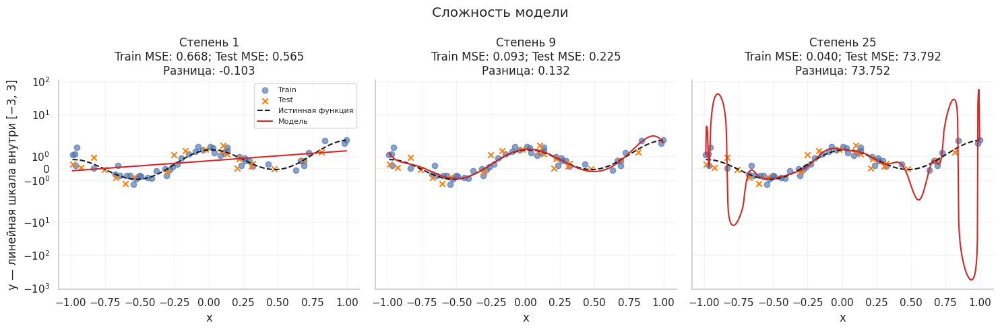

In [17]:
degree_models = {f'Степень {degree}': polynomial_model(degree, LinearRegression()).fit(x_train, y_train) for degree in [1, 9, 25]}

compare_models(degree_models,'Сложность модели')

### Переобучение и недообучение

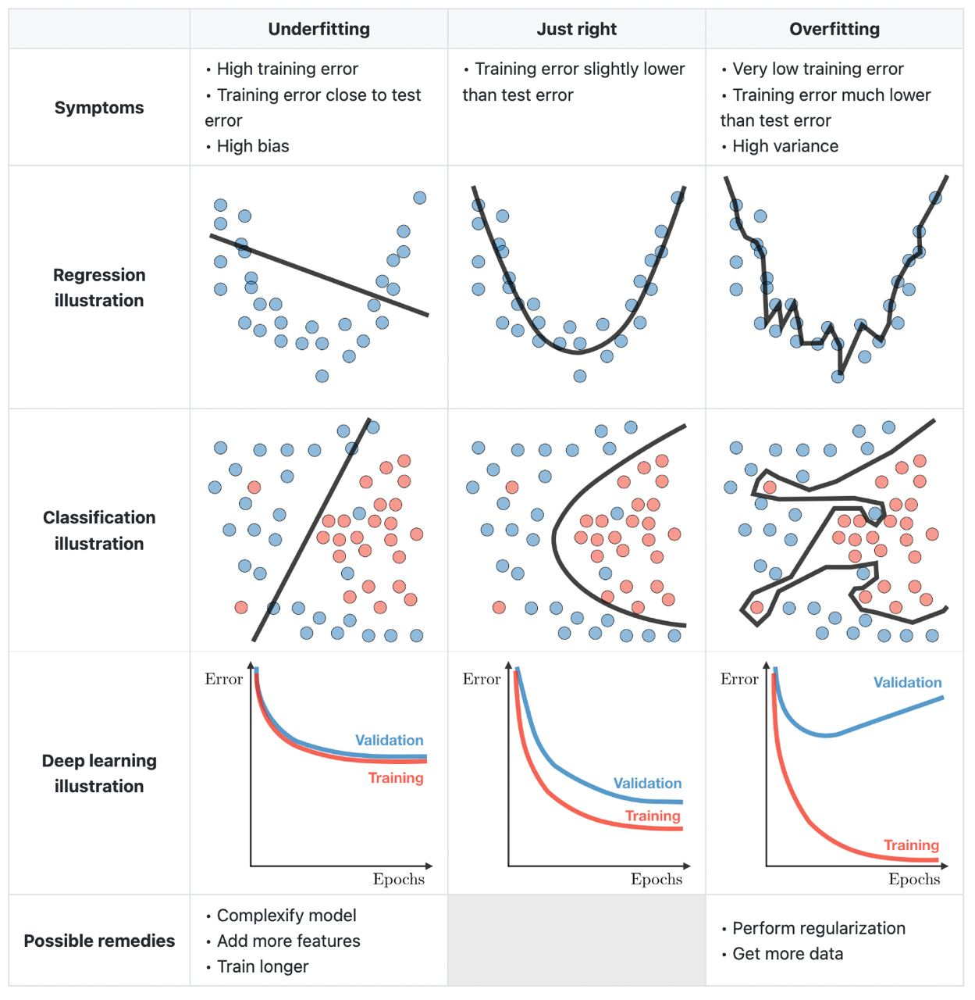

### Регуляризация

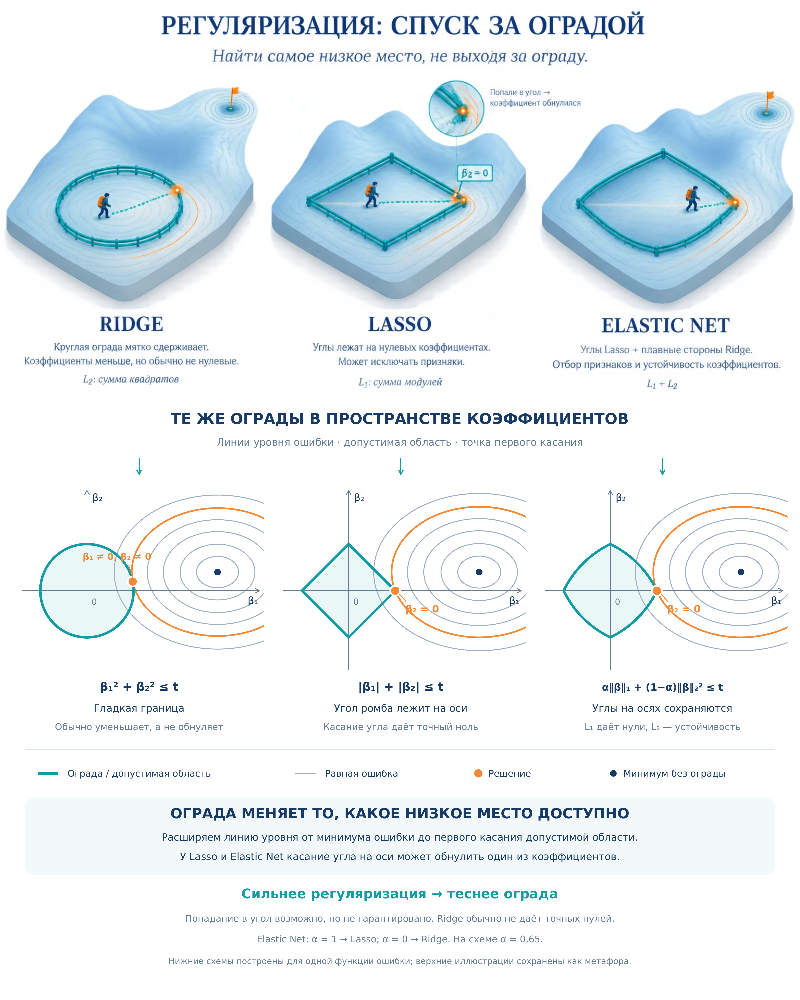

In [18]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

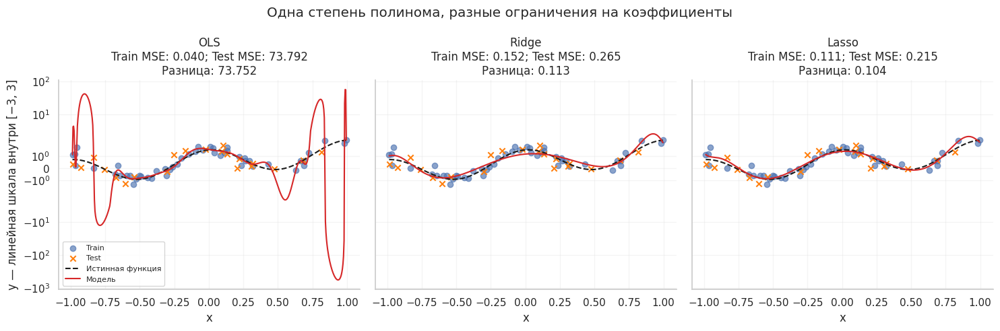

In [19]:
regularized_models = {'OLS': degree_models['Степень 25']}
regularized_models['Ridge'] = polynomial_model(25, Ridge(solver='svd', alpha=0.1)).fit(x_train, y_train)
regularized_models['Lasso'] = polynomial_model(25, Lasso(max_iter=500000, tol=1e-4, alpha=0.001)).fit(x_train, y_train)

regularization_metrics = compare_models(regularized_models, 'Одна степень полинома, разные ограничения на коэффициенты')

In [20]:
coefficients = pd.DataFrame({name: model[-1].coef_ for name, model in regularized_models.items()}, index=np.arange(1, 26))
coefficients.index.name = 'Степень признака'

coefficient_summary = pd.DataFrame({
    'L1-норма': coefficients.abs().sum(),
    'L2-норма': np.sqrt(coefficients.pow(2).sum()),
    'Максимальный |w|': coefficients.abs().max(),
    'Нулевых коэффициентов': coefficients.eq(0).sum(),
    'Ненулевых коэффициентов': coefficients.ne(0).sum(),
})

coefficient_summary.round(4)

,L1-норма,L2-норма,Максимальный |w|,Нулевых коэффициентов,Ненулевых коэффициентов
OLS,1.745376e+08,5.685335e+07,2.881874e+07,0,25
Ridge,1.334000e+01,4.556900e+00,3.082800e+00,0,25
Lasso,1.780390e+01,9.768900e+00,7.861000e+00,16,9


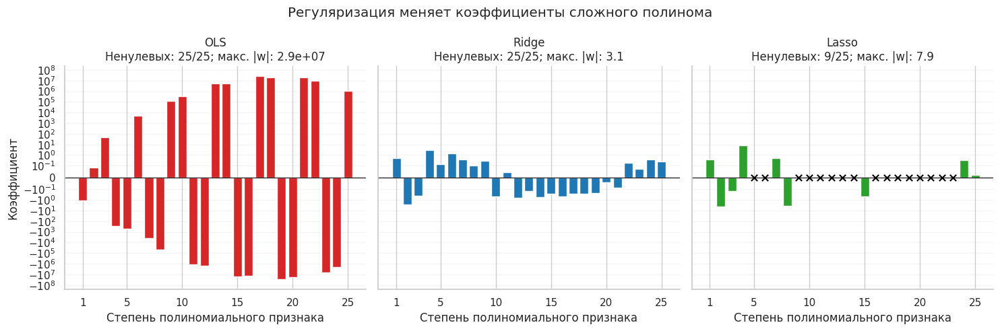

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
colors = ['tab:red', 'tab:blue', 'tab:green']

for ax, name, color in zip(axes, coefficients.columns, colors):
    weights = coefficients[name]
    zeros = weights[weights == 0]

    ax.bar(weights.index, weights, color=color)
    ax.scatter(zeros.index, zeros.values, color='black', marker='x', s=45, zorder=3)

    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_yscale('symlog', linthresh=0.1)
    ax.set_xticks([1, 5, 10, 15, 20, 25])
    ax.set_title(f'{name}\nНенулевых: {weights.ne(0).sum()}/25; макс. |w|: {weights.abs().max():.2g}')
    ax.set_xlabel('Степень полиномиального признака')
    ax.grid(axis='y', alpha=0.2)

axes[0].set_ylabel('Коэффициент')
fig.suptitle('Регуляризация меняет коэффициенты сложного полинома')
plt.tight_layout()
plt.show()

### Реальная задача

Возьмем задачу посложнее - предсказание возраста морского гребешка

Rings - value + 1.5 gives age in years (eg. 4 = 5.5 years)

In [22]:
abalone_source = 'https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data'
abalone_columns = ['sex', 'length', 'diameter', 'height', 'whole_weight', 'shucked_weight', 'viscera_weight', 'shell_weight', 'rings']
abalone_data = pd.read_csv(abalone_source, header=None, names=abalone_columns)
abalone_data.head()

,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [23]:
train_val, test = train_test_split(abalone_data, test_size=0.2, random_state=2026)

# 25% от оставшихся 80% = 20% исходных данных на валидацию
train, val = train_test_split(train_val, test_size=0.25, random_state=2026)
train = train.copy()
val = val.copy()

y_train = train["rings"]
y_val = val["rings"]
y_test = test["rings"]

#### Обработаем категориальные переменные

In [24]:
encoder = OneHotEncoder(drop="first", handle_unknown="error",sparse_output=False)

cat_train = encoder.fit_transform(train[["sex"]])
cat_val = encoder.transform(val[["sex"]])
cat_test = encoder.transform(test[["sex"]])

cat_names = encoder.get_feature_names_out(["sex"])

examples = pd.DataFrame({"sex": ["F", "I", "M"]})
examples[cat_names] = encoder.transform(examples)
examples

,sex,sex_I,sex_M
0,F,0.0,0.0
1,I,1.0,0.0
2,M,0.0,1.0


#### Добавим масштабирование

In [25]:
cols = ['length', 'diameter', 'height', 'whole_weight', 'shucked_weight', 'viscera_weight', 'shell_weight']
feature_names = cols + list(cat_names)

scaler = StandardScaler()
x_train = scaler.fit_transform(train[cols])
x_val = scaler.transform(val[cols])

abalone_prepared_train = pd.DataFrame(np.c_[x_train, cat_train], index=train.index, columns=feature_names)
abalone_prepared_validation = pd.DataFrame(np.c_[x_val, cat_val], index=val.index, columns=feature_names)

abalone_prepared_train.head()

,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,sex_I,sex_M
1144,0.473343,0.481725,0.233257,0.596491,0.544719,0.326985,0.196597,0.0,1.0
1739,1.264242,1.187498,0.460881,0.944447,0.979359,0.875908,0.843431,0.0,1.0
1917,0.639848,0.683374,0.233257,0.341939,0.132834,0.363580,0.525434,0.0,1.0
799,-0.817071,-0.627347,-0.677237,-0.938006,-1.055031,-0.903517,-0.873028,0.0,0.0
659,0.514969,0.683374,1.029939,0.277275,0.262544,-0.167045,0.666364,0.0,0.0


#### Обучим первую модель

In [26]:
abalone_lr = LinearRegression().fit(abalone_prepared_train, y_train)
train_mean = y_train.mean()

rows = []
for split, x, y in [
    ('train', abalone_prepared_train, y_train),
    ('validation', abalone_prepared_validation, y_val),
]:
    for model, prediction in [
        ('Среднее train', np.full(len(y), train_mean)),
        ('LR', abalone_lr.predict(x)),
    ]:
        rows.append({'model': model, 'split': split, 'rmse': np.sqrt(mean_squared_error(y, prediction)), 'mae': mean_absolute_error(y, prediction)})

abalone_initial_metrics = pd.DataFrame(rows)
abalone_initial_metrics.round(4)

,model,split,rmse,mae
0,Среднее train,train,3.2198,2.3701
1,LR,train,2.1977,1.5934
2,Среднее train,validation,3.2818,2.3533
3,LR,validation,2.2458,1.5843


#### Интерпретация

Для стандартизированного числового столбца коэффициент показывает изменение прогноза на одно обучающее стандартное отклонение признака при фиксированных остальных входах. Для `sex_I` и `sex_M` сдвиг относительно F при тех же числовых признаках.

In [27]:
abalone_coefficient_table = pd.DataFrame({'feature': feature_names, 'coefficient': abalone_lr.coef_})
abalone_coefficient_table

,feature,coefficient
0,length,-0.071438
1,diameter,1.309901
2,height,0.308283
3,whole_weight,4.301287
4,shucked_weight,-4.502134
5,viscera_weight,-1.079987
6,shell_weight,1.250678
7,sex_I,-0.869143
8,sex_M,0.031015


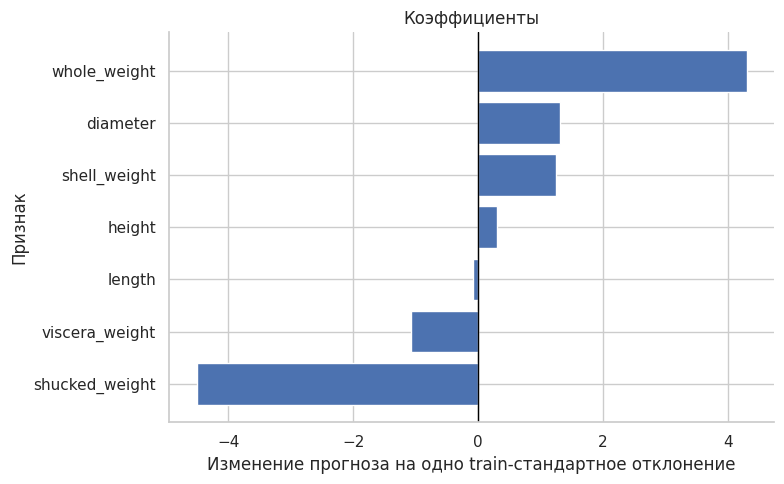

In [28]:
abalone_numeric_coefficients = abalone_coefficient_table.loc[abalone_coefficient_table['feature'].isin(cols)].sort_values('coefficient')

plt.figure(figsize=(8, 5))
plt.barh(abalone_numeric_coefficients['feature'], abalone_numeric_coefficients['coefficient'])
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Изменение прогноза на одно train-стандартное отклонение')
plt.ylabel('Признак')
plt.title('Коэффициенты')
plt.tight_layout()
plt.show()

Коэффициент стандартизированного числового признака показывает, на сколько изменится прогноз при увеличении исходного признака на одно стандартное отклонение, рассчитанное на train (скейлером), если остальные входы остаются неизменными.

Например, если стандартное отклонение length на train = 0.1, а коэффициент стандартизированной длины = 1.2, увеличение length на 0.1 повысит прогноз на 1.2 единицы целевой переменной. Увеличение на 0.05 - на 0.6.

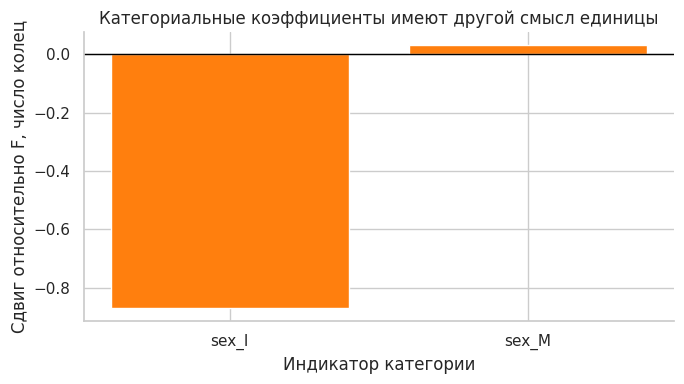

In [29]:
abalone_category_coefficients = abalone_coefficient_table.loc[abalone_coefficient_table['feature'].isin(cat_names)]

plt.figure(figsize=(7, 4))
plt.bar(abalone_category_coefficients['feature'], abalone_category_coefficients['coefficient'], color='tab:orange')
plt.axhline(0, color='black', linewidth=1)
plt.ylabel('Сдвиг относительно F, число колец')
plt.xlabel('Индикатор категории')
plt.title('Категориальные коэффициенты имеют другой смысл единицы')
plt.tight_layout()
plt.show()

Если при OHE категория F удалена и выбрана базовой, а столбцы sex_I и sex_M остаются в виде 0/1, их коэффициенты показывают сдвиг прогноза относительно F при одинаковых остальных входах.

Например, sex_I = −1.5 означает, что прогноз для категории I на 1.5 единицы целевой переменной ниже, чем для F, а sex_M = 0.4 - что прогноз для M на 0.4 выше.

##### Наглядная иллюстрация

| Категория | sex_I | sex_M |
| --------- | ----- | ----- |
| F         | 0     | 0     |
| I         | 1     | 0     |
| M         | 0     | 1     |

$y​=10+1.2length−1.5sexI +0.4sexM$

При длине = 0:

| Категория | Прогноз |
| --------- | ------- |
| F         | 10      |
| I         | 8.5     |
| M         | 10.4    |

То есть:
- коэффициент sex_I = -1.5 - прогноз для I ниже прогноза для F на 1.5
- коэффициент sex_M = 0.4 - прогноз для M выше прогноза для F на 0.4


#### Мультиколлинеарность






Мультиколлинеарность — наличие линейной зависимости между объясняющими переменными (факторами) регрессионной модели. При этом различают полную коллинеарность, которая означает наличие функциональной (тождественной) линейной зависимости и частичную или просто мультиколлинеарность — наличие сильной корреляции между факторами.

Проблемы:

*   Мультиколлинеарность может стать причиной переобучаемости модели, что приведет к неверному результату
*   Оценки параметров ненадежны – получаются большие стандартные ошибки, которые меняются с изменением объема наблюдений, что делает модель регрессии непригодной для прогнозирования.

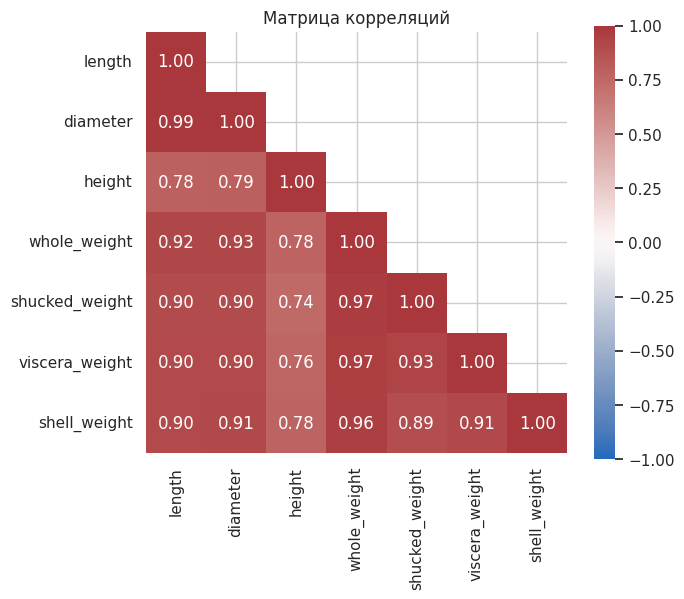

In [30]:
train_correlations = train[cols].corr()
correlation_mask = np.triu(np.ones_like(train_correlations, dtype=bool), k=1)

plt.figure(figsize=(7, 6))
sns.heatmap(train_correlations, mask=correlation_mask, vmin=-1, vmax=1, center=0, cmap='vlag', annot=True, fmt='.2f', square=True)
plt.title('Матрица корреляций')
plt.tight_layout()
plt.show()

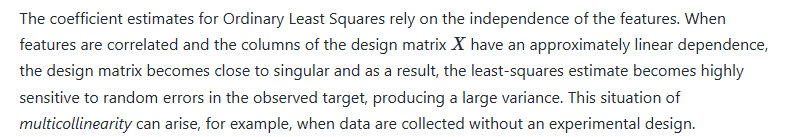

In [31]:
threshold = 0.95
selected = []

for column in train[cols]:
    if not (train_correlations.loc[column, selected].abs() > threshold).any():
        selected.append(column)

selected

['length', 'height', 'whole_weight']

In [32]:
columns = abalone_prepared_train.columns

models = {
    'OLS': (make_pipeline(StandardScaler(), LinearRegression()),columns),
    'Отбор + OLS': (make_pipeline(StandardScaler(), LinearRegression()), selected + list(cat_names)),
    'ElasticNet': (make_pipeline(ElasticNet(alpha=0.005, l1_ratio=0.99)), columns),
}

noise_rng = np.random.default_rng(72)
predictions = {name: [] for name in models}
rows = []

for repetition in range(80):
    y = np.asarray(y_train) + noise_rng.normal(0, 0.1, len(y_train))

    for name, (model, features) in models.items():
        model.fit(abalone_prepared_train[features], y)
        prediction = model.predict(abalone_prepared_validation[features])
        weights = model[-1].coef_
        predictions[name].append(prediction)

        rows.append({
            'method': name,
            'repetition': repetition,
            'n_features': len(features),
            'n_nonzero': np.count_nonzero(weights),
            'rmse': np.sqrt(mean_squared_error(y_val, prediction)),
            **dict(zip(features, weights)),
        })

results = pd.DataFrame(rows)

In [33]:
grouped = results.groupby('method')
coefficient_std = grouped[columns].std(ddof=0)

summary = pd.DataFrame({
    'Среднее число ненулевых признаков': grouped['n_nonzero'].mean(),
    'Макс. std коэффициента': coefficient_std.max(axis=1),
    'Средняя std прогноза': pd.Series({
        name: np.std(values, axis=0).mean()
        for name, values in predictions.items()
    }),
    'Средняя validation RMSE': grouped['rmse'].mean(),
})

summary.round(4)

,Среднее число ненулевых признаков,Макс. std коэффициента,Средняя std прогноза,Средняя validation RMSE
ElasticNet,8.0,0.0214,0.0056,2.2469
OLS,9.0,0.0216,0.0059,2.2458
Отбор + OLS,5.0,0.0051,0.0045,2.6385
